In [69]:
%load_ext autoreload
%autoreload 2
import emcee
import corner
import pickle
import time
from astropy.table import QTable
from astropy import units as u
from astropy import constants as const

from multiprocessing import Pool

import numpy as np
from matplotlib import pyplot as plt


from nfw_profile_heating import NFWProfile
from statistics_functions import chi_squared
from plotting import savefig, paper_plot
from load_data_and_var import load_data_and_var

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [71]:
reflex_clean, _ = load_data_and_var()
reflex_clean.head()

,MCXC,OName,AName,Ah Am RAs Ed Em Es,RAdeg DEdeg,GLON GLAT,z_x,Cat,Sub-Cat,Scale,...,E_MSZ,e_MSZ,RedMAPPer,ACT,SPT,ISE,AMIevi,O,Comment,L_err
1,J0003.1-0605,RXCJ0003.1-0605,A2697,0 3 11.8 - 6 5 10,0.799 -6.086,92.169 -66.033,0.2320,NORAS/REFLEX,REFLEX,3.698,...,0.368165,0.369144,RMJ000311.6-060530.1,,,-10,-1000.0,1,NaN,0.617909
2,J0003.8+0203,RXCJ0003.8+0203,A2700,0 3 50.6 + 2 3 48,0.961 2.063,99.610 -58.637,0.0924,NORAS/REFLEX,REFLEX,1.719,...,0.282160,0.301448,RMJ000349.7+020359.3,,,-10,-1000.0,0,NaN,0.147037
3,J0006.0-3443,RXCJ0006.0-3443,A2721,0 6 3.0 -34 43 27,1.513 -34.724,352.147 -77.668,0.1147,NORAS/REFLEX,REFLEX,2.080,...,0.248869,0.226974,,,,-10,-1000.0,1,NaN,0.227619
6,J0011.3-2851,RXCJ0011.3-2851,A2734,0 11 20.7 -28 51 18,2.836 -28.855,19.562 -80.986,0.0620,NORAS/REFLEX,REFLEX,1.195,...,0.182667,0.188038,,,,-10,-1000.0,1,NaN,0.092959
9,J0013.6-1930,RXCJ0013.6-1930,A0013,0 13 38.3 -19 30 8,3.409 -19.502,72.276 -78.456,0.0940,NORAS/REFLEX,REFLEX,1.746,...,0.233331,0.245311,,,,-10,-1000.0,1,NaN,0.133542


Text(0, 0.5, '$\\mathrm{Number~of~Clusters}$')

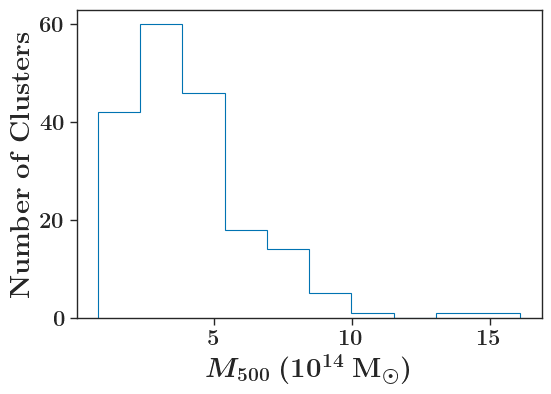

In [85]:
paper_plot()
fig = plt.figure()
plt.hist(reflex_clean['MSZ'], histtype='step')
plt.xlabel(f'$M_{{500}} ~ (10^{{14}} ~\mathrm{{M_{{\odot}}}})$')
plt.ylabel(f'$\mathrm{{Number~of~Clusters}}$')

Text(0, 0.5, '$\\mathrm{Number~of~Clusters}$')

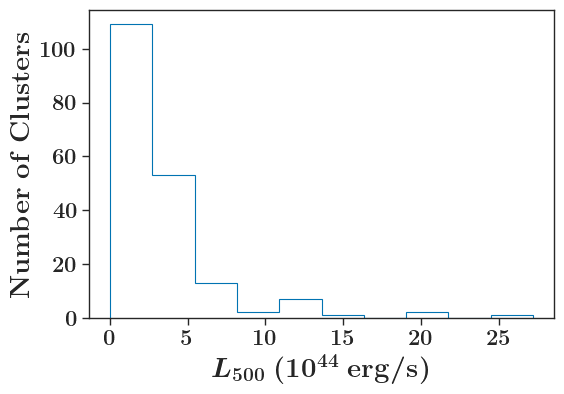

In [83]:


#plt.xlabel(f'$L500 (10^{{14}} Msun)$')
plt.hist(reflex_clean['L500'], histtype='step')
plt.xlabel(f'$L_{{500}}~ (10^{{44}} ~ \mathrm{{erg/s}})$')
plt.ylabel(f'$\mathrm{{Number~of~Clusters}}$')

Text(0, 0.5, '$\\mathrm{Number~of~Clusters}$')

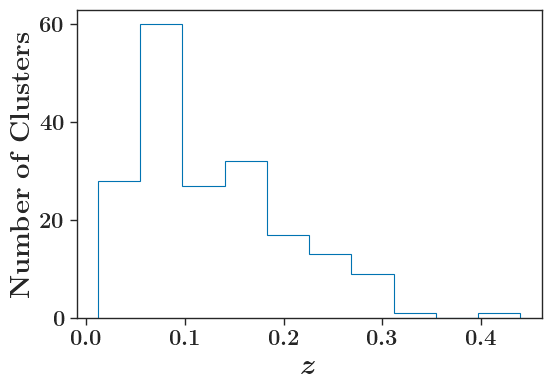

In [87]:
plt.hist(reflex_clean['z_y'], histtype='step')
plt.xlabel(f'$z$')
plt.ylabel(f'$\mathrm{{Number~of~Clusters}}$')

In [75]:
reflex_clean

,MCXC,OName,AName,Ah Am RAs Ed Em Es,RAdeg DEdeg,GLON GLAT,z_x,Cat,Sub-Cat,Scale,...,E_MSZ,e_MSZ,RedMAPPer,ACT,SPT,ISE,AMIevi,O,Comment,L_err
1,J0003.1-0605,RXCJ0003.1-0605,A2697,0 3 11.8 - 6 5 10,0.799 -6.086,92.169 -66.033,0.2320,NORAS/REFLEX,REFLEX,3.698,...,0.368165,0.369144,RMJ000311.6-060530.1,,,-10,-1000.0,1,NaN,0.617909
2,J0003.8+0203,RXCJ0003.8+0203,A2700,0 3 50.6 + 2 3 48,0.961 2.063,99.610 -58.637,0.0924,NORAS/REFLEX,REFLEX,1.719,...,0.282160,0.301448,RMJ000349.7+020359.3,,,-10,-1000.0,0,NaN,0.147037
3,J0006.0-3443,RXCJ0006.0-3443,A2721,0 6 3.0 -34 43 27,1.513 -34.724,352.147 -77.668,0.1147,NORAS/REFLEX,REFLEX,2.080,...,0.248869,0.226974,,,,-10,-1000.0,1,NaN,0.227619
6,J0011.3-2851,RXCJ0011.3-2851,A2734,0 11 20.7 -28 51 18,2.836 -28.855,19.562 -80.986,0.0620,NORAS/REFLEX,REFLEX,1.195,...,0.182667,0.188038,,,,-10,-1000.0,1,NaN,0.092959
9,J0013.6-1930,RXCJ0013.6-1930,A0013,0 13 38.3 -19 30 8,3.409 -19.502,72.276 -78.456,0.0940,NORAS/REFLEX,REFLEX,1.746,...,0.233331,0.245311,,,,-10,-1000.0,1,NaN,0.133542
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
543,J2347.7-2808,RXCJ2347.7-2808,A4038,23 47 43.2 -28 8 29,356.930 -28.141,25.139 -75.862,0.0300,NORAS/REFLEX,REFLEX,0.601,...,0.114748,0.107849,,,,-10,-1000.0,1,NaN,0.038488
546,J2351.6-2605,RXCJ2351.6-2605,A2667,23 51 40.7 -26 5 1,357.919 -26.084,34.017 -76.609,0.2264,NORAS/REFLEX,REFLEX,3.631,...,0.365168,0.382711,,,,-10,-1000.0,1,NaN,0.993468
547,J2354.2-1024,RXCJ2354.2-1024,A2670,23 54 13.4 -10 24 46,358.556 -10.413,81.334 -68.530,0.0765,NORAS/REFLEX,REFLEX,1.450,...,0.216913,0.225417,RMJ235413.7-102508.5,,,-10,-1000.0,1,NaN,0.151354
549,J2357.0-3445,RXCJ2357.0-3445,A4059,23 57 2.3 -34 45 38,359.260 -34.761,356.359 -76.082,0.0475,NORAS/REFLEX,REFLEX,0.931,...,0.163126,0.149009,,,,-10,-1000.0,1,NaN,0.091267


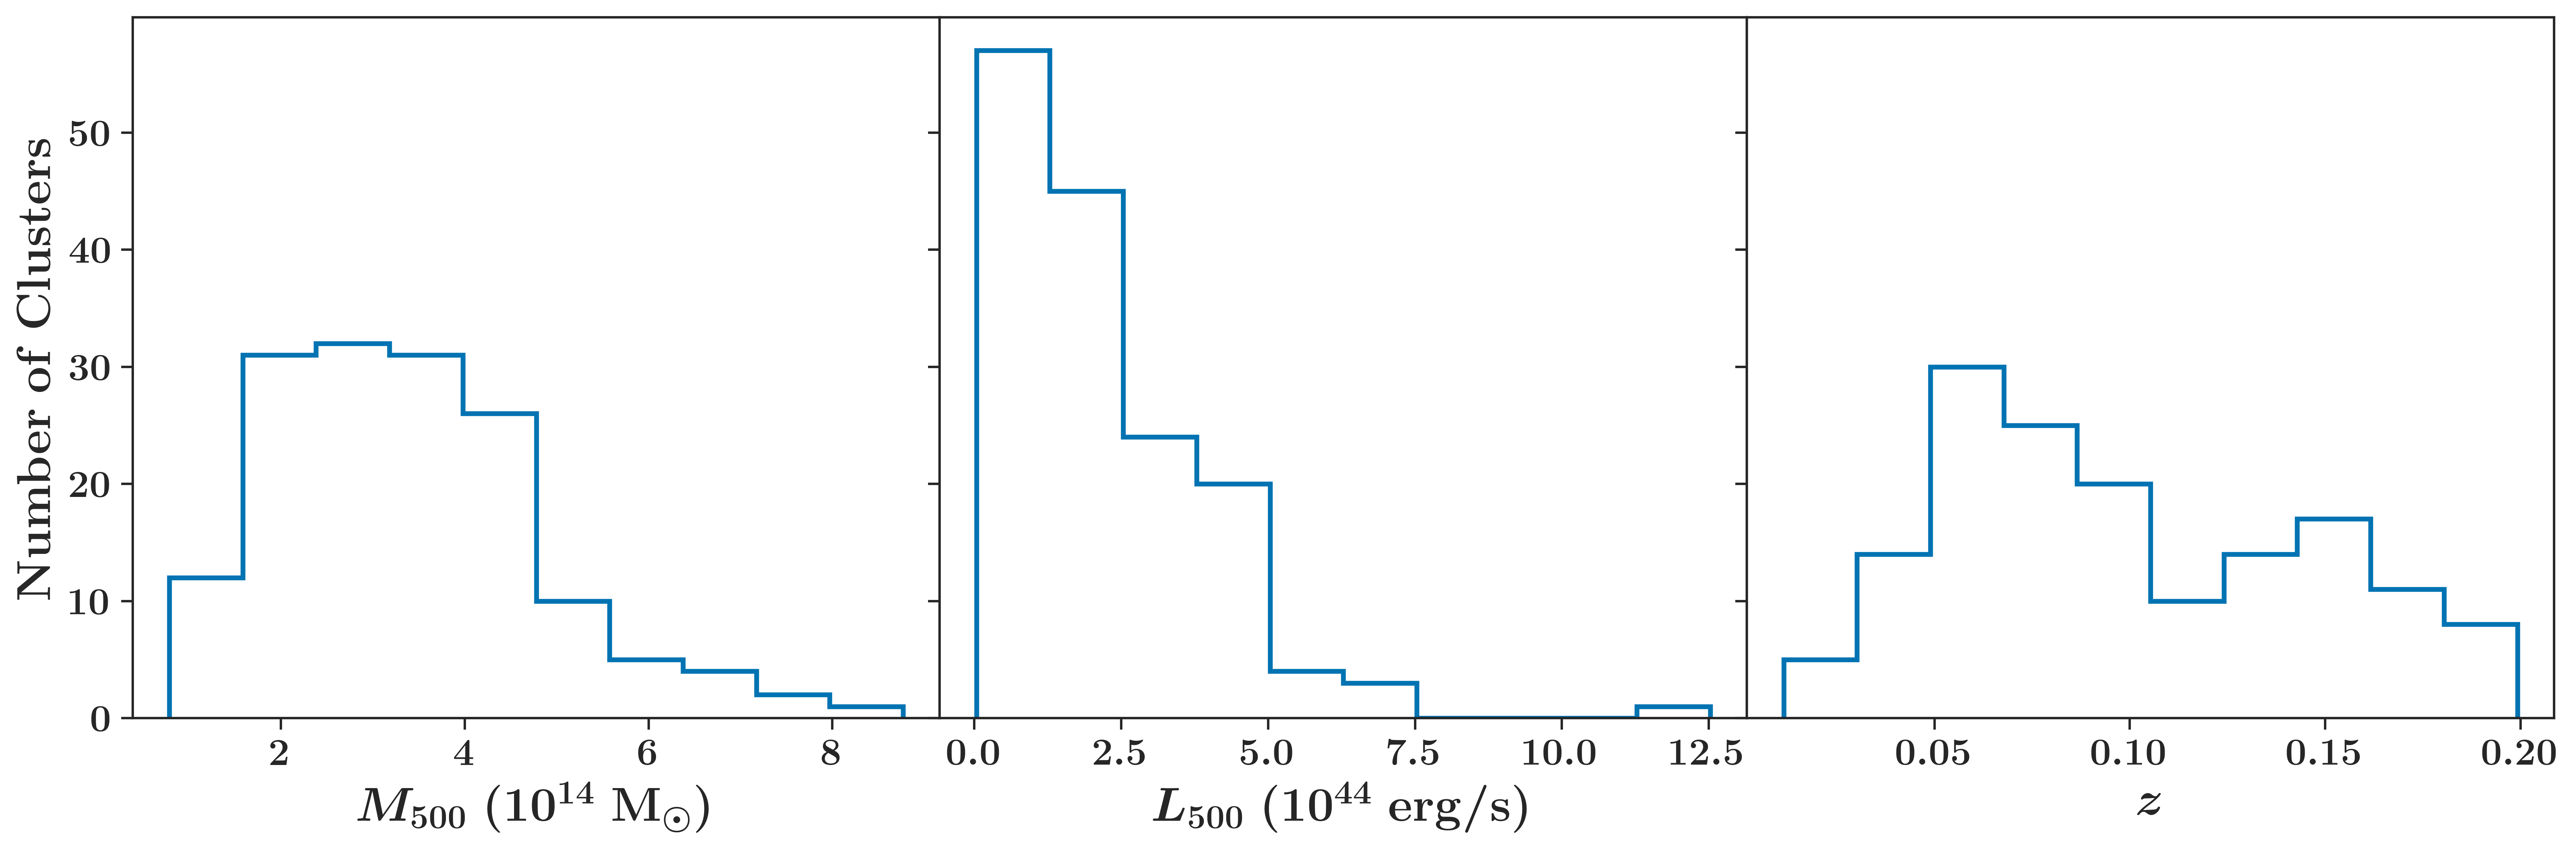

In [96]:
    lowz_data = reflex_clean[reflex_clean['z_y'] < 0.2]
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, gridspec_kw={'wspace': 0}, dpi=450)  # 1 row, 3 columns

    # First subplot
    axes[0].hist(lowz_data['MSZ'], histtype='step', lw=2)
    axes[0].set_xlabel(f'$M_{{500}} ~ (10^{{14}} ~\\mathrm{{M_{{\\odot}}}})$')
    axes[0].set_ylabel(f'$\\mathrm{{Number~of~Clusters}}$')

    # Second subplot
    axes[1].hist(lowz_data['L500'], histtype='step', lw=2)
    axes[1].set_xlabel(f'$L_{{500}}~ (10^{{44}} ~ \\mathrm{{erg/s}})$')
    #axes[1].set_ylabel(f'$\\mathrm{{Number~of~Clusters}}$')

    # Third subplot
    axes[2].hist(lowz_data['z_y'], histtype='step', lw=2)
    axes[2].set_xlabel(f'$z$')
    #axes[2].set_ylabel(f'$\\mathrm{{Number~of~Clusters}}$')

    plt.tight_layout()  # Adjusts the layout so the labels and titles fit within the figure
    plt.show()
    fig.savefig('plots/REFLEX_clusters.pdf', bbox_inches='tight')